In [1]:
'''
Exploratory Data Analysis for B.C. Data

By Anita Taylor

Date: 2023/10/08

'''

'\nExploratory Data Analysis for B.C. Data\n\nBy Anita Taylor\n\nDate: 2023/10/08\n\n'

In [2]:
'''
Questions: 

Is my outlier removal too harsh?
Is my data overfitted?

'''

'\nQuestions: \n\nIs my outlier removal too harsh?\nIs my data overfitted?\n\n'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
import seaborn as sns
from scipy import stats
from scipy.stats import norm


**Copy this next cell for future scripts:**


In [2]:
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number','LONGITUDE','LATITUTE']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'

#Datat = Datat.dropna()    #Uncomment this 
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
#one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer') #Uncomment both for regression, etc
#Datat = pd.concat([Datat, one_hot_df], axis=1)
Datawithtime = Datat.copy()
DropDF2 = ['Aquifer Subtype', 'DATE', 'OBSWELL', 'year_month']
Datat = Datat.drop(DropDF2, axis=1, errors='ignore')


In [17]:
Datat.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'Precip_Climatology',
       'Tn_Climatology', 'Tx_Climatology', 'FD', 'HW', 'MT', 'Aquifer Group'],
      dtype='object')

## Copy This 

Use for to analyses Climate change factors:

Target metals are 'As-T', 'U--T', 'Mn-T', 'Pb-T'

In [ ]:
#Datasets for climate change factors
#Drought Analysis
df_Drought = Datat[Datat['FD'] < 0]
#Flood Analysis
df_flood = Datat[Datat['FD'] > 0]
#Rising Temperatures - nighttime temp
df_Heatmin = Datat[Datat['MT'] > 0]
#Rising Temperatures - daytime temp
df_Heatmax = Datat[Datat['HW'] > 0]
#Seawater Intrusion
df_SWICLorSCorSC = Datat[(Datat['Chlrid:D'] > 150) | (Datat['Specific Conductance'] > 1000)]


In [18]:
len(Datat.columns)

27

In [19]:
Datat.shape

(1147, 27)

In [3]:
DatatAS = Datat [(Datat ['As-T'] >= 0.01)]
DatatAS.shape

(81, 27)

In [4]:
DataMn = Datat [(Datat ['Mn-T'] >= 0.12)]
DataMn.shape

(344, 27)

In [5]:
DataPb = Datat [(Datat ['Pb-T'] >= 0.005)]
DataPb.shape

(289, 27)

In [6]:
DataU = Datat [(Datat ['U--T'] >= 0.02)]
DataU.shape

(6, 27)

In [7]:
DataSC = Datat [(Datat ['Specific Conductance'] >= 1000)]
DataSC.shape

(107, 27)

In [8]:
DataTD = Datat [(Datat ['Residue Filterable 1.0u'] >= 750)]
DataTD.shape

(79, 27)

In [9]:
DataC = Datat [(Datat ['Chlrid:D'] >= 150)]
DataC.shape

(52, 27)

**Copy this next cell for future scripts:**

In [3]:
Datat = Datat.dropna()
Datat.shape

(985, 27)

In [21]:
DropDF3 = ['Aquifer Subtype']
Datawithtime = Datawithtime.drop(DropDF3, axis=1, errors='ignore')
Datawithtime = Datawithtime.dropna()
Datawithtime.shape

(985, 30)

In [22]:
'''
Summary Statistics

Source:
https://numpy.org/doc/stable/reference/generated/numpy.nanstd.html
https://numpy.org/doc/stable/reference/generated/numpy.nanvar.html
https://numpy.org/doc/stable/reference/generated/numpy.nanstd.html
https://www.sharpsightlabs.com/blog/numpy-axes-explained/

Descriptive Statistics
Sources: 
https://stackoverflow.com/questions/22235245/calculate-summary-statistics-of-columns-in-dataframe
https://www.askpython.com/python/examples/calculate-summary-statistics
https://pandas.pydata.org/docs/getting_started/intro_tutorials/06_calculate_statistics.html
https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.kurtosis.html
'''

# import pandas and numpy if they're not already imported
import pandas as pd
import numpy as np

# assuming `df` is your DataFrame
selected_columns = Datat.iloc[:, :26]  # select the first 26 columns
group_column = Datat.iloc[:, 26]  # select the 27th column

# group the selected columns by the values in the group column
grouped = selected_columns.groupby(group_column)

# get the unique group names
groups = Datat.iloc[:, 26].unique()

# calculate summary statistics and percentiles for each group
all_summaries = []  # list to hold summary dataframes for each group
for group in groups:
    # select data for this group
    this_group = grouped.get_group(group)

    # calculate summary statistics
    summary = this_group.agg(['mean', 'var', 'std', 'min', 'max', 'skew', 'median', pd.DataFrame.kurt])

    # calculate percentiles and add them to the summary
    for q in [0.1, 0.5, 0.9]:
        summary.loc[f'{q*100}% percentile'] = this_group.quantile(q)

    # calculate coefficient of variation and add it to the summary
    summary.loc['cv'] = this_group.std() / this_group.mean()

    # add the group name as the top level of the index
    summary.index = pd.MultiIndex.from_product([[group], summary.index])

    # add this group's summary to the list
    all_summaries.append(summary)

# concatenate all the group summaries into one DataFrame
summary_df = pd.concat(all_summaries)

# save to CSVWhich is the best given datasets have range between 0.000001-0.027475 in one column and 3580.000000-0.025000 in another?


summary_df.to_csv('summary.csv')

# check the DataFrame
print(summary_df)

                    Alkalinity Total 4.5       As-T         Ca-T       Cd-T  \
1 mean                         90.776677   0.005205    33.376070   0.001795   
  var                        7015.844068   0.000595  1480.591406   0.000037   
  std                          83.760636   0.024394    38.478454   0.006105   
  min                           0.500000   0.000010     0.050000   0.000005   
  max                         485.000000   0.250000   659.000000   0.065000   
  skew                          2.264677   8.495163     9.312726   6.996989   
  median                       62.000000   0.000200    24.600000   0.000016   
  kurt                          5.257215  80.431253   141.267189  60.855489   
  10.0% percentile             30.000000   0.000050     8.888000   0.000005   
  50.0% percentile             62.000000   0.000200    24.600000   0.000016   
  90.0% percentile            211.400000   0.004700    63.820000   0.006000   
  cv                            0.922711   4.686348 

In [23]:
#summary_df(len(Datat.columns)

**Copy this next cell for future scripts:**

In [4]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID datat style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''
def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH','Alkalinity Total 4.5', 'Residue Filterable 1.0u', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
        'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'Precip_Climatology',
       'Tn_Climatology', 'Tx_Climatology',]

cleaned_dataset_array1 = replace_outliers_with_iqr(Datat[numeric_cols1], 1.5)
Datat[numeric_cols1] = cleaned_dataset_array1

def replace_loweroutliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
    return cleaned_dataset
                                                                                               
numeric_cols1a = ['U--T', 'Residue Filterable 1.0u', 'Chlrid:D']
                                                                                               

                                        

def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[outliers, col] = upper_threshold
        outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[outliers, col] = lower_threshold
    return cleaned_dataset

# Assume Datat is your DataFrame
#numeric_cols = [ 'FD', 'HW', 'MT']

# Call your function on just the numeric columns
#cleaned_dataset_array = replace_outliers_with_threshold(Datat[numeric_cols], threshold_multiplier=3)

# Convert the numpy array back to a DataFrame
#cleaned_dataset = pd.DataFrame(cleaned_dataset_array, columns=numeric_cols, index=Datat.index)

#Datat[numeric_cols] = cleaned_dataset

Datatpastremoval1 = Datat.copy() #This is incase I screw up. Can be commented out.

#cleaned_dataset.to_csv('cleaned_dataset.csv')

KeyError: "None of [Index([('R', 'e', 's', 'i', 'd', 'u', 'e', ' ', 'F', 'i', 'l', 't', 'e', 'r', 'a', 'b', 'l', 'e', ' ', '1', '.', '0', 'u'), ('R', 'e', 's', 'i', 'd', 'u', 'e', ' ', 'F', 'i', 'l', 't', 'e', 'r', 'a', 'b', 'l', 'e', ' ', '1', '.', '0', 'u')], dtype='object')] are in the [index]"

In [25]:
'''
Normalization/Scaling
'''
from sklearn.preprocessing import FunctionTransformer, StandardScaler
import pandas as pd
import numpy as np

Datat1 = Datat.copy()
columns_to_transform = ['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T']
# Apply the log1p transformation to the selected columns
for col in columns_to_transform:
    Datat1.loc[:, col] = np.log1p(Datat1[col])
    
# assuming `df` is your DataFrame
selected_columns = Datat1.iloc[:, :26]  # select the first 26 columns
group_column = Datat1.iloc[:, 26]  # select the 27th column

# group the selected columns by the values in the group column
grouped = selected_columns.groupby(group_column)

# get the unique group names
groups = Datat1.iloc[:, 26].unique()

# calculate summary statistics and percentiles for each group
all_summaries2 = []  # list to hold summary dataframes for each group
for group in groups:
    # select data for this group
    this_group = grouped.get_group(group)

    # calculate summary statistics
    summary = this_group.agg(['mean', 'var', 'std', 'min', 'max', 'skew', 'median', pd.DataFrame.kurt])

    # calculate percentiles and add them to the summary
    for q in [0.1, 0.5, 0.9]:
        summary.loc[f'{q*100}% percentile'] = this_group.quantile(q)

    # calculate coefficient of variation and add it to the summary
    summary.loc['cv'] = this_group.std() / this_group.mean()

    # add the group name as the top level of the index
    summary.index = pd.MultiIndex.from_product([[group], summary.index])

    # add this group's summary to the list
    all_summaries2.append(summary)

# concatenate all the group summaries into one DataFrame
summary_df2 = pd.concat(all_summaries2)

# save to CSVWhich is the best given datasets have range between 0.000001-0.027475 in one column and 3580.000000-0.025000 in another?


summary_df2.to_csv('summary2logafteroutlier.csv')

# check the DataFrame
print(summary_df2)

                    Alkalinity Total 4.5      As-T      Ca-T          Cd-T  \
1 mean                          4.232096  0.001259  3.233779  1.289255e-04   
  var                           0.515347  0.000003  0.507167  5.195191e-08   
  std                           0.717876  0.001750  0.712157  2.279296e-04   
  min                           0.405465  0.000010  0.048790  4.999988e-06   
  max                           5.993961  0.005286  4.578570  6.033180e-04   
  skew                          0.323382  1.357920 -0.304344  1.571820e+00   
  median                        4.143135  0.000200  3.242592  1.639987e-05   
  kurt                          1.310850  0.343478  0.364692  5.311968e-01   
  10.0% percentile              3.433987  0.000050  2.291321  4.999988e-06   
  50.0% percentile              4.143135  0.000200  3.242592  1.639987e-05   
  90.0% percentile              5.358469  0.004689  4.171612  6.033180e-04   
  cv                            0.169627  1.389423  0.220224  1.

In [26]:
Datat.head()

,Alkalinity Total 4.5,As-T,Ca-T,Cd-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,...,PRECIPITATION,MIN_TEMP,MAX_TEMP,Precip_Climatology,Tn_Climatology,Tx_Climatology,FD,HW,MT,Aquifer Group
0,272.0,0.00530,96.375,0.000603,39.75,3.01,0.0970,0.240,0.092,0.03000,...,60.4,8.693548,22.290323,37.8343,9.659100,26.3532,22.5657,-4.062877,-0.965552,1
1,336.0,0.00530,96.375,0.000603,39.75,4.49,0.1090,0.005,0.106,0.04172,...,44.6,10.596774,26.032258,49.5586,10.127000,26.4905,-4.9586,-0.458242,0.469774,1
2,371.0,0.00290,96.375,0.000010,39.75,5.16,0.1100,0.200,0.100,0.00029,...,53.7,6.096774,21.709677,45.1616,4.920920,19.5059,8.5384,2.203777,1.175854,1
3,365.0,0.00300,96.375,0.000010,39.75,3.59,0.0969,0.160,0.099,0.00003,...,109.0,3.161290,12.306452,41.9559,0.998876,12.0534,67.0441,0.253052,2.162414,1
4,350.0,0.00249,96.375,0.000005,39.75,1.78,0.0955,0.140,0.064,0.00002,...,44.5,10.693548,27.903226,37.8343,9.659100,26.3532,6.6657,1.550026,1.034448,1


**Copy this next cell for future scripts:**

In [6]:
from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP','Precip_Climatology','Tn_Climatology', 'Tx_Climatology']
# Apply the transformation to the specified columns
Datat[cols_to_transform] = pt.fit_transform(Datat[cols_to_transform])

In [28]:
Datat.head()

,Alkalinity Total 4.5,As-T,Ca-T,Cd-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,...,PRECIPITATION,MIN_TEMP,MAX_TEMP,Precip_Climatology,Tn_Climatology,Tx_Climatology,FD,HW,MT,Aquifer Group
0,1.252988,1.677243,1.781862,1.678044,1.517344,1.104648,0.387082,0.657125,0.877092,1.618282,...,-0.042370,0.516933,0.903721,-0.805805,0.912163,1.621408,22.5657,-4.062877,-0.965552,1
1,1.556872,1.677243,1.781862,1.678044,1.517344,1.328472,0.510849,-1.199072,1.033549,1.728926,...,-0.317572,0.945556,1.437158,-0.426507,1.020412,1.641924,-4.9586,-0.458242,0.469774,1
2,1.704274,1.223570,1.781862,-0.666136,1.517344,1.396059,0.520657,0.461012,0.969606,-0.583253,...,-0.152170,-0.051185,0.821059,-0.556452,-0.150096,0.601223,8.5384,2.203777,1.175854,1
3,1.679801,1.256337,1.781862,-0.666136,1.517344,1.208605,0.386002,0.228797,0.958509,-0.639051,...,0.573396,-0.662643,-0.512327,-0.659886,-0.958277,-0.500788,67.0441,0.253052,2.162414,1
4,1.617211,1.069170,1.781862,-0.734597,1.517344,0.750916,0.370790,0.096652,0.474990,-0.641224,...,-0.319513,0.967591,1.704315,-0.805805,0.912163,1.621408,6.6657,1.550026,1.034448,1


In [29]:
'''
Final summary statistics 
'''

# import pandas and numpy if they're not already imported
import pandas as pd
import numpy as np

# assuming `df` is your DataFrame
selected_columns = Datat.iloc[:, :26]  # select the first 26 columns
group_column = Datat.iloc[:, 26]  # select the 27th column

# group the selected columns by the values in the group column
grouped = selected_columns.groupby(group_column)

# get the unique group names
groups = Datat.iloc[:, 26].unique()

# calculate summary statistics and percentiles for each group
all_summaries3 = []  # list to hold summary dataframes for each group
for group in groups:
    # select data for this group
    this_group = grouped.get_group(group)

    # calculate summary statistics
    summary = this_group.agg(['mean', 'var', 'std', 'min', 'max', 'skew', 'median', pd.DataFrame.kurt])

    # calculate percentiles and add them to the summary
    for q in [0.1, 0.5, 0.9]:
        summary.loc[f'{q*100}% percentile'] = this_group.quantile(q)

    # calculate coefficient of variation and add it to the summary
    summary.loc['cv'] = this_group.std() / this_group.mean()

    # add the group name as the top level of the index
    summary.index = pd.MultiIndex.from_product([[group], summary.index])

    # add this group's summary to the list
    all_summaries3.append(summary)

# concatenate all the group summaries into one DataFrame
summary_df3 = pd.concat(all_summaries3)

# save to CSVWhich is the best given datasets have range between 0.000001-0.027475 in one column and 3580.000000-0.025000 in another?


summary_df3.to_csv('summary3afteroutlierYJ2.csv')

# check the DataFrame
print(summary_df3)

                    Alkalinity Total 4.5       As-T       Ca-T       Cd-T  \
1 mean                         -0.367880  -0.166208   0.037265  -0.135547   
  var                           0.622845   1.048058   0.651192   0.818318   
  std                           0.789205   1.023747   0.806965   0.904610   
  min                          -3.156503  -1.115611  -2.527070  -0.734597   
  max                           1.818376   1.677243   1.781862   1.678044   
  skew                          0.888944   0.786283   0.227888   1.396323   
  median                       -0.519785  -0.827094  -0.023967  -0.581230   
  kurt                          0.663415  -1.027256  -0.165345   0.143425   
  10.0% percentile             -1.195601  -1.052388  -0.987524  -0.734597   
  50.0% percentile             -0.519785  -0.827094  -0.023967  -0.581230   
  90.0% percentile              0.908408   1.611660   1.166567   1.678044   
  cv                           -2.145280  -6.159432  21.654607  -6.673792   

In [ ]:
'''
Heatmap for OLS model
'''



In [30]:
'''
Correlation matrix

Source: 

https://likegeeks.com/python-correlation-matrix/
https://medium.com/analytics-vidhya/kendall-rank-correlation-python-19524cb0e9a0

'''

#Dataset for Paper2 

df_Aq1 = Datat[Datat['Aquifer Group'] = 1]
df_Aq2 = Datat[Datat['Aquifer Group'] = 2]
df_Aq3 = Datat[Datat['Aquifer Group'] = 3]

correlation_mat = Datat.corr()
correlation_mat.to_csv('correlation_matafteroutlier.csv')

print(correlation_mat)



                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.331478  0.476150 -0.035799   
As-T                                 0.331478  1.000000  0.215813  0.193565   
Ca-T                                 0.476150  0.215813  1.000000 -0.110594   
Cd-T                                -0.035799  0.193565 -0.110594  1.000000   
Chlrid:D                             0.367084 -0.036564  0.236882  0.062593   
Fe-T                                -0.077360  0.185005 -0.128132  0.469906   
Mn-T                                 0.146621  0.326953  0.160546  0.259720   
N.Kjel:T                             0.167984  0.025695  0.074672  0.068153   
P--T                                 0.118968  0.314992  0.024557  0.069917   
Pb-T                                 0.000493  0.220065 -0.145472  0.953947   
Residue Filterable 1.0u              0.740985  0.229934  0.571131  0.013260   
Specific Conductance                 0.810783  0.242

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_32588\4005023904.py:11: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_mat = Datat.corr()


In [ ]:
correlation_mataq1 = df_Aq1.corr()
correlation_mataq1.to_csv('correlation_matafteroutlieraq1.csv')

correlation_mataq2 = df_Aq2.corr()
correlation_mataq2.to_csv('correlation_matafteroutlieraq2.csv')

correlation_mataq3 = df_Aq3.corr()
correlation_mataq3.to_csv('correlation_matafteroutlieraq3.csv')

In [31]:
correlation_tau = Datat.corr(method='kendall')
print(correlation_tau)
correlation_tau.to_csv('correlation_tauafteroutlier.csv')



C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_32588\1674711377.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_tau = Datat.corr(method='kendall')


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.285920  0.411349 -0.100220   
As-T                                 0.285920  1.000000  0.176207  0.065111   
Ca-T                                 0.411349  0.176207  1.000000 -0.071955   
Cd-T                                -0.100220  0.065111 -0.071955  1.000000   
Chlrid:D                             0.236016 -0.007701  0.178555  0.094562   
Fe-T                                -0.078202  0.126663 -0.105842  0.372378   
Mn-T                                 0.078743  0.215586  0.076246  0.167808   
N.Kjel:T                             0.098307  0.005792  0.060000  0.007722   
P--T                                 0.130985  0.274213  0.027103  0.100996   
Pb-T                                 0.027456  0.186251 -0.050186  0.563172   
Residue Filterable 1.0u              0.631592  0.200057  0.526888  0.003200   
Specific Conductance                 0.682992  0.203

In [ ]:
correlation_tauaq1 = df_Aq1.corr(method='kendall')
correlation_tauaq1.to_csv('correlation_tauafteroutlieraq1.csv')

correlation_tauaq2 = df_Aq2.corr(method='kendall')
correlation_tauaq2.to_csv('correlation_tauafteroutlieraq2.csv')

correlation_tauaq3 = df_Aq3.corr(method='kendall')
correlation_tauaq3.to_csv('correlation_tauafteroutlieraq3.csv')


In [32]:
correlation_rho = Datat.corr(method='spearman')
correlation_rho.to_csv('correlation_rhoafteroutlier.csv')
print(correlation_rho)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.414026  0.537470 -0.130432   
As-T                                 0.414026  1.000000  0.254451  0.085988   
Ca-T                                 0.537470  0.254451  1.000000 -0.103922   
Cd-T                                -0.130432  0.085988 -0.103922  1.000000   
Chlrid:D                             0.332710 -0.011730  0.254289  0.128594   
Fe-T                                -0.111032  0.182722 -0.148650  0.502434   
Mn-T                                 0.108584  0.317879  0.116420  0.225915   
N.Kjel:T                             0.140625  0.010575  0.082483  0.013573   
P--T                                 0.187921  0.387008  0.038149  0.139198   
Pb-T                                 0.037253  0.250322 -0.079011  0.717752   
Residue Filterable 1.0u              0.791422  0.283774  0.641696 -0.000676   
Specific Conductance                 0.841517  0.290

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_32588\780527307.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_rho = Datat.corr(method='spearman')


In [ ]:
correlation_rhoaq1 = df_Aq1.corr(method='spearman')
correlation_rhoaq1.to_csv('correlation_rhoafteroutlieraq1.csv')

correlation_rhoaq2 = df_Aq2.corr(method='spearman')
correlation_rhoaq2.to_csv('correlation_rhoafteroutlieraq2.csv')

correlation_rhoaq3 = df_Aq1.corr(method='spearman')
correlation_rhoaq3.to_csv('correlation_rhoafteroutlieraq3.csv')

In [33]:
print(Datat.dtypes)


Alkalinity Total 4.5       float64
As-T                       float64
Ca-T                       float64
Cd-T                       float64
Chlrid:D                   float64
Fe-T                       float64
Mn-T                       float64
N.Kjel:T                   float64
P--T                       float64
Pb-T                       float64
Residue Filterable 1.0u    float64
Specific Conductance       float64
Sulfat:D                   float64
pH                         float64
Hardness Total (T)         float64
K--T                       float64
U--T                       float64
PRECIPITATION              float64
MIN_TEMP                   float64
MAX_TEMP                   float64
Precip_Climatology         float64
Tn_Climatology             float64
Tx_Climatology             float64
FD                         float64
HW                         float64
MT                         float64
Aquifer Group               object
dtype: object


In [34]:
Datat.shape

(985, 27)

In [35]:
'''
Handling Multivariant Outliers

Notes:  
Mahalanobis method.  May not be normalized by idc so is down after scaling.

Source:
https://towardsdatascience.com/multivariate-outlier-detection-in-high-dimensional-spectral-data-45878fd0ccb8
https://www.kaggle.com/code/xiaodongdong/mahalanobis-distance
https://www.kaggle.com/code/karimzakir02/outlier-detection-techniques


'''

# Critical values for two degrees of freedom
from scipy.stats import chi2 
from scipy.spatial.distance import mahalanobis

import pandas as pd
import numpy as np
from scipy.stats import chi2 
from scipy.spatial.distance import mahalanobis

one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer')
Datat = pd.concat([Datat, one_hot_df], axis=1)
Dropman = ['Aquifer Group']
Dataman = Datat.drop(Dropman, axis=1, errors='ignore')


Mahalanobisd = Dataman.to_numpy()

# Finding the inverse of the covariance matrix and the data's center
cov_matrix = Dataman.cov()

# Regularization: Add a small constant on the diagonal
regularized_cov = cov_matrix + np.eye(cov_matrix.shape[0]) * 1e-6
inv_cov = np.linalg.inv(regularized_cov)
mean = Dataman.mean(axis=0)


# Initialize an empty list to store the Mahalanobis distances
mahalanobis_distances = []

# Calculate the distance for each row
for index, row in Dataman.iterrows():
    mahalanobis_dist = mahalanobis(row, mean, inv_cov)**2
    mahalanobis_distances.append(mahalanobis_dist)
    
# Add the distances to the DataFrame
Dataman["mahalanobis_distance"] = mahalanobis_distances

# Finding the 0.99 cut-off (two-tailed) and identifying outliers
mahalanobis_threshold = chi2.ppf(0.99, Datat.shape[1] - 1)
mahalanobis_outliers = Dataman[Dataman["mahalanobis_distance"] > mahalanobis_threshold].index

print("Removed:", len(mahalanobis_outliers))
print(f"This is {len(mahalanobis_outliers) / Dataman.shape[0] * 100}% of our dataset")

Removed: 75
This is 7.614213197969544% of our dataset


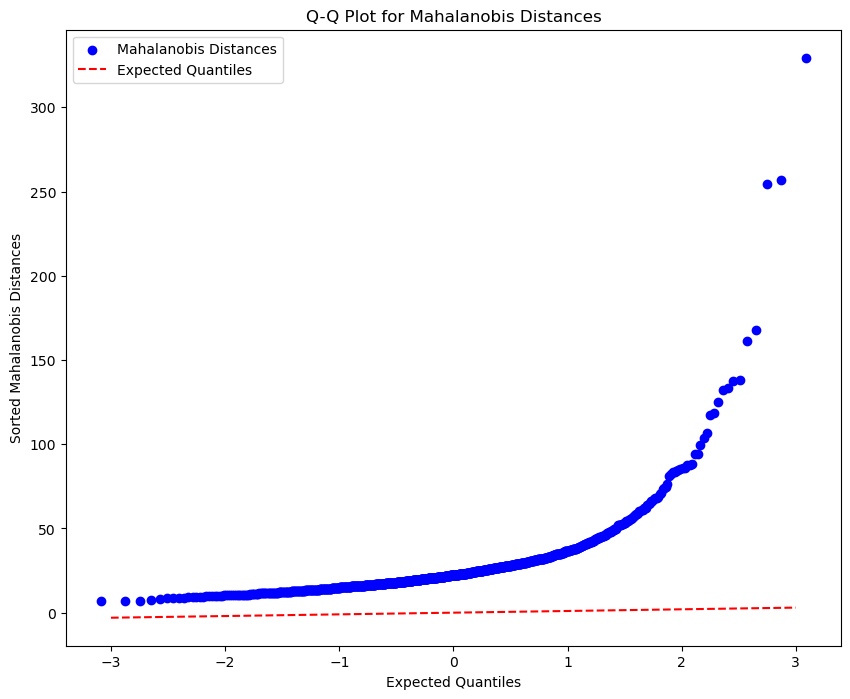

<Figure size 1000x800 with 0 Axes>

In [36]:
from scipy.stats import norm
import matplotlib.pyplot as plt

def create_mahalanobis_qq_plot(df):
    # Use pre-computed Mahalanobis distances
    mahalanobis_distances = df["mahalanobis_distance"].values

    # Sort the Mahalanobis distances
    sorted_distances = np.sort(mahalanobis_distances)

    # Calculate expected quantiles based on a normal distribution
    expected_quantiles = norm.ppf(np.arange(1, len(sorted_distances) + 1) / (len(sorted_distances) + 1))

    # Plot the Q-Q plot
    plt.scatter(expected_quantiles, sorted_distances, color='b', label='Mahalanobis Distances')
    plt.plot([-3, 3], [-3, 3], color='r', linestyle='--', label='Expected Quantiles')
    plt.xlabel('Expected Quantiles')
    plt.ylabel('Sorted Mahalanobis Distances')
    plt.title('Q-Q Plot for Mahalanobis Distances')
    plt.legend()
    plt.show()
    
create_mahalanobis_qq_plot(Dataman)
plt.savefig('Figures/qqmahalanobisplot.png') 

In [37]:
Datat.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'Precip_Climatology',
       'Tn_Climatology', 'Tx_Climatology', 'FD', 'HW', 'MT', 'Aquifer Group',
       'Aquifer_1', 'Aquifer_2', 'Aquifer_3'],
      dtype='object')

# Probably here is were the bug starts

In [38]:
Datawithtime_copy = Datawithtime.copy()
Datawithtime_copy.update(Datatpastremoval1)
Datawithtime_copy.columns

Index(['OBSWELL', 'DATE', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T',
       'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T',
       'Residue Filterable 1.0u', 'Specific Conductance', 'Sulfat:D', 'pH',
       'Hardness Total (T)', 'K--T', 'U--T', 'year_month', 'PRECIPITATION',
       'MIN_TEMP', 'MAX_TEMP', 'Precip_Climatology', 'Tn_Climatology',
       'Tx_Climatology', 'FD', 'HW', 'MT', 'Aquifer Group'],
      dtype='object')

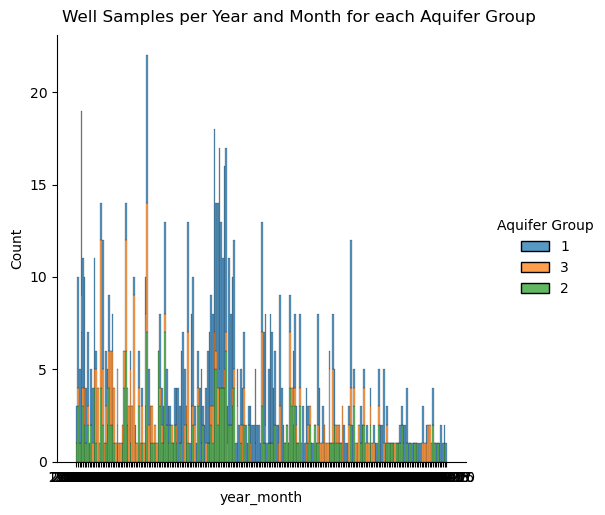

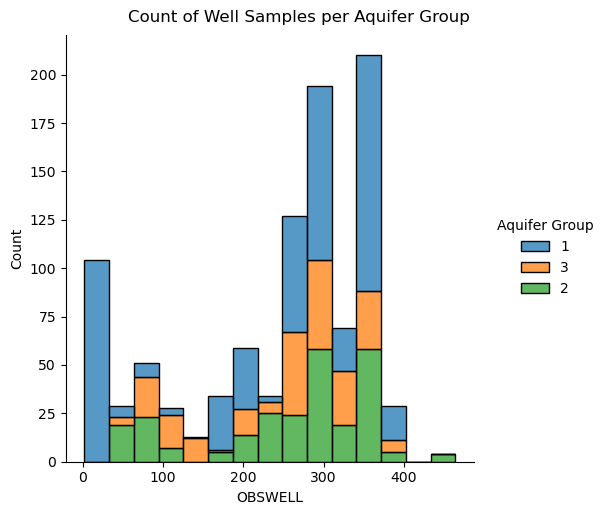

In [39]:
'''
Plots

Source: 
https://seaborn.pydata.org/generated/seaborn.pairplot.html
https://seaborn.pydata.org/generated/seaborn.displot.html
https://seaborn.pydata.org/archive/0.11/tutorial/axis_grids.html

https://towardsdatascience.com/histograms-vs-kdes-explained-ed62e7753f12

'''
Datawithtime.update(Datat)
ttplot =sns.displot(data=Datawithtime, x="year_month", hue="Aquifer Group", multiple="stack")
ttplot.fig.suptitle("Well Samples per Year and Month for each Aquifer Group", y=1.02)
plt.savefig('Figures/displotyearmonth.png') 

dtplot = sns.displot(data=Datawithtime, x="OBSWELL", hue='Aquifer Group', multiple="stack")
dtplot.fig.suptitle("Count of Well Samples per Aquifer Group", y=1.02)
plt.savefig('Figures/displotOBSWELL.png') 

In [40]:
Datawithtime.columns

Index(['OBSWELL', 'DATE', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T',
       'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T',
       'Residue Filterable 1.0u', 'Specific Conductance', 'Sulfat:D', 'pH',
       'Hardness Total (T)', 'K--T', 'U--T', 'year_month', 'PRECIPITATION',
       'MIN_TEMP', 'MAX_TEMP', 'Precip_Climatology', 'Tn_Climatology',
       'Tx_Climatology', 'FD', 'HW', 'MT', 'Aquifer Group'],
      dtype='object')

In [41]:
Datawithtime.columns

Index(['OBSWELL', 'DATE', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T',
       'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T',
       'Residue Filterable 1.0u', 'Specific Conductance', 'Sulfat:D', 'pH',
       'Hardness Total (T)', 'K--T', 'U--T', 'year_month', 'PRECIPITATION',
       'MIN_TEMP', 'MAX_TEMP', 'Precip_Climatology', 'Tn_Climatology',
       'Tx_Climatology', 'FD', 'HW', 'MT', 'Aquifer Group'],
      dtype='object')

In [42]:
Metals_Total = Datat[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group']]

Metals_Total.shape

(985, 6)

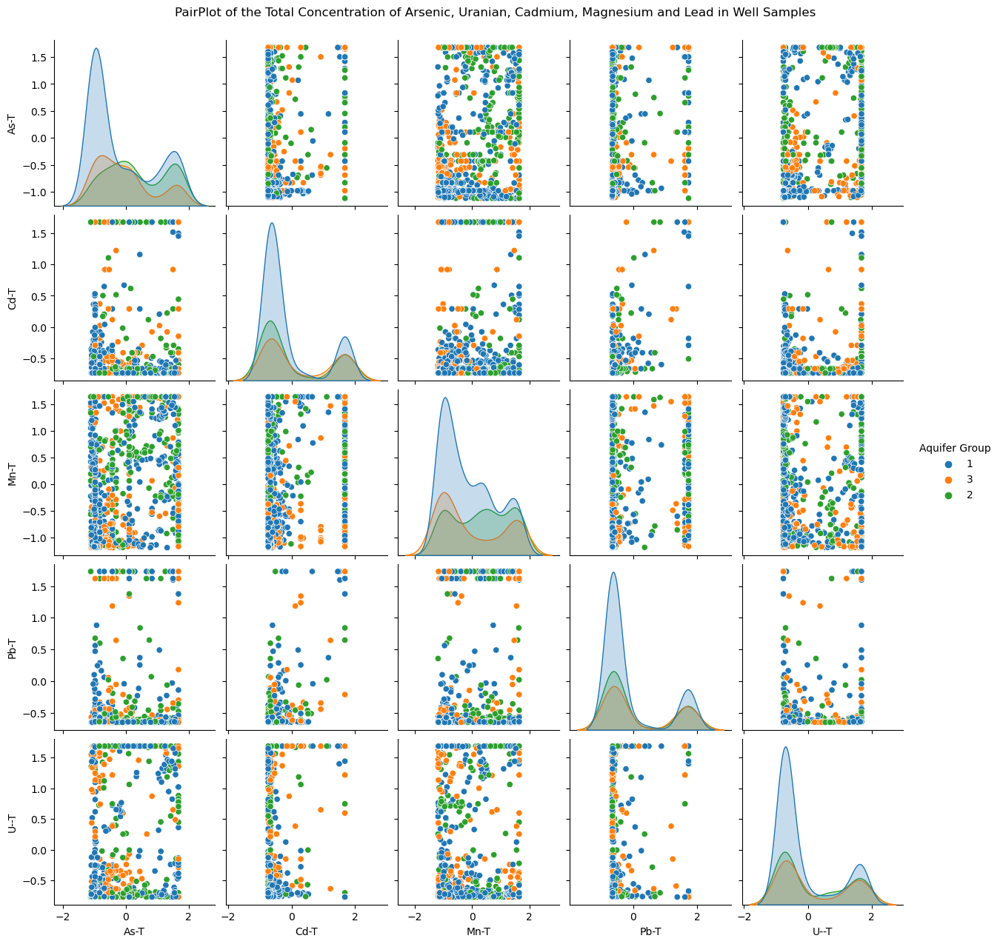

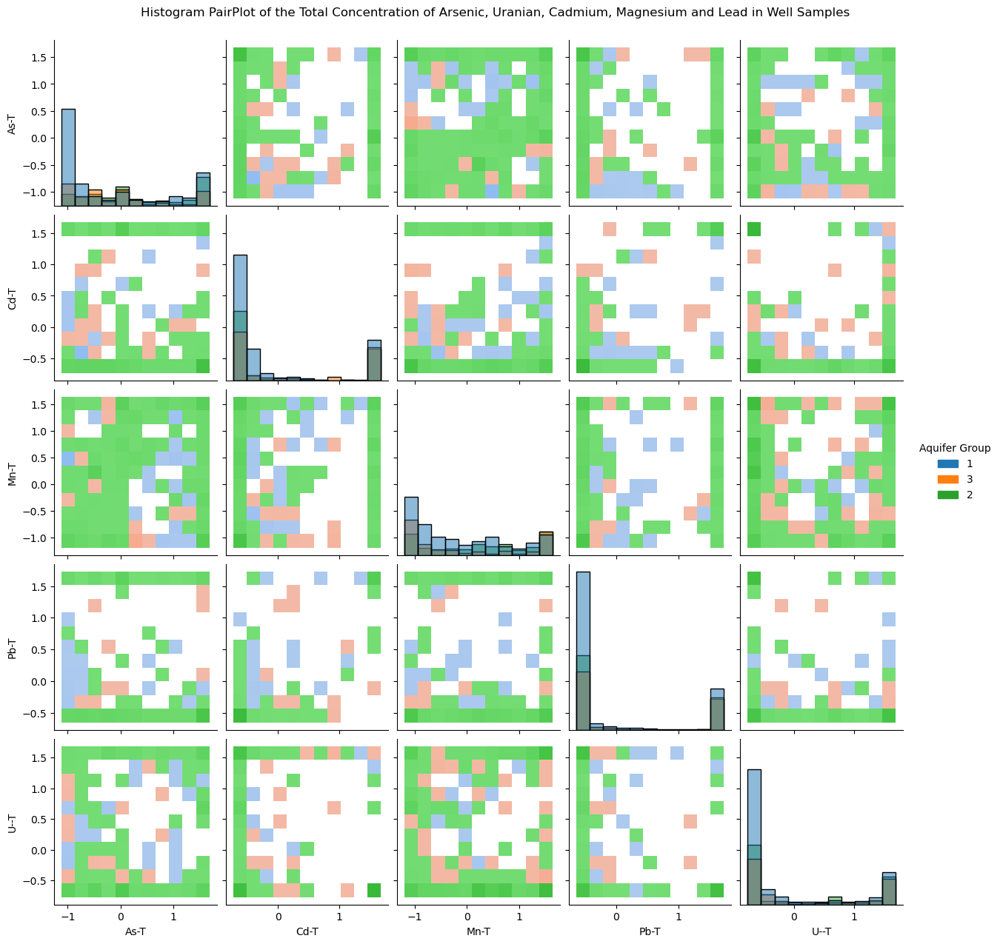

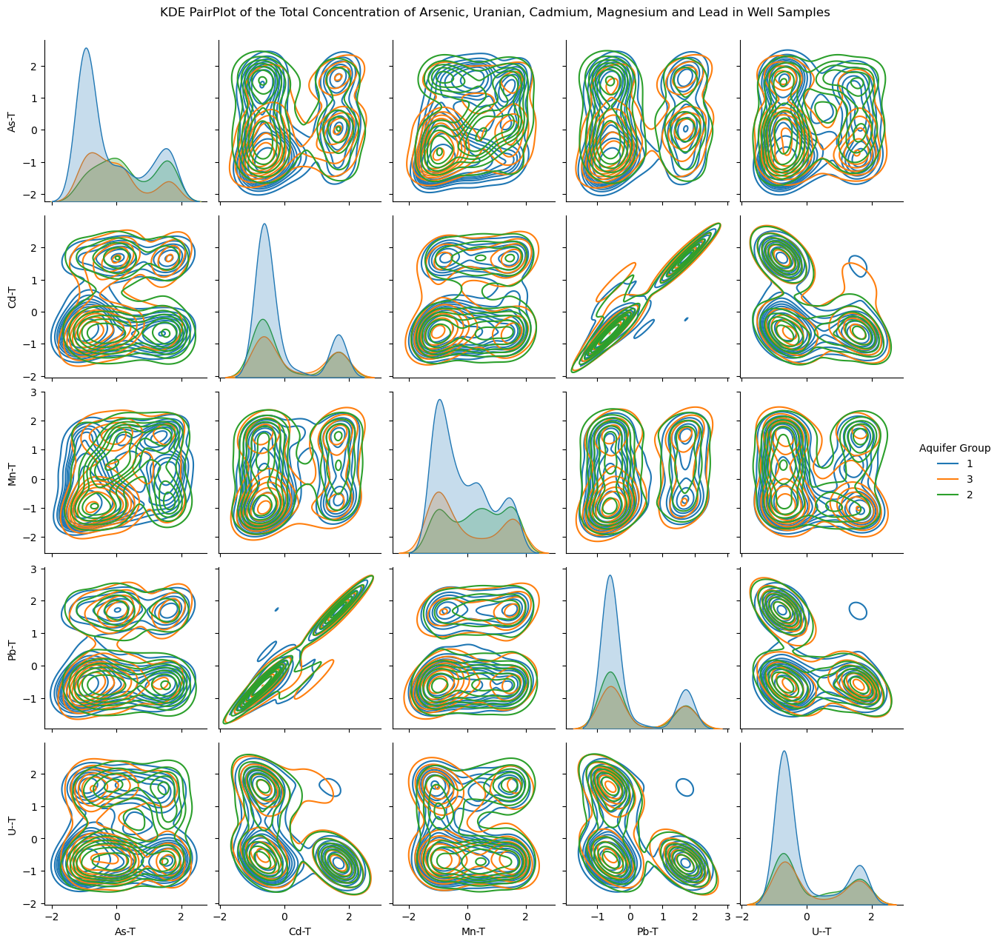

In [43]:
Metalsg = sns.pairplot(Metals_Total, hue="Aquifer Group")
Metalsg.fig.suptitle("PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples", y=1.02)
plt.savefig('Figures/pairplotmetals.png') # Save the first figure

Metalsh = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="hist")
Metalsh.fig.suptitle("Histogram PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples", y=1.02)
plt.savefig('Figures/histplotmetals.png') 

Metalsf = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="kde")
Metalsf.fig.suptitle("KDE PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Samples", y=1.02)
plt.savefig('Figures/KDEplotmetals.png') 


In [44]:
Precept = Datat[['FD', 'HW', 'MT', 'Aquifer Group', 'PRECIPITATION', 'Precip_Climatology', 'MAX_TEMP', 'Tx_Climatology', 'MIN_TEMP']]
Precept.shape

(985, 9)

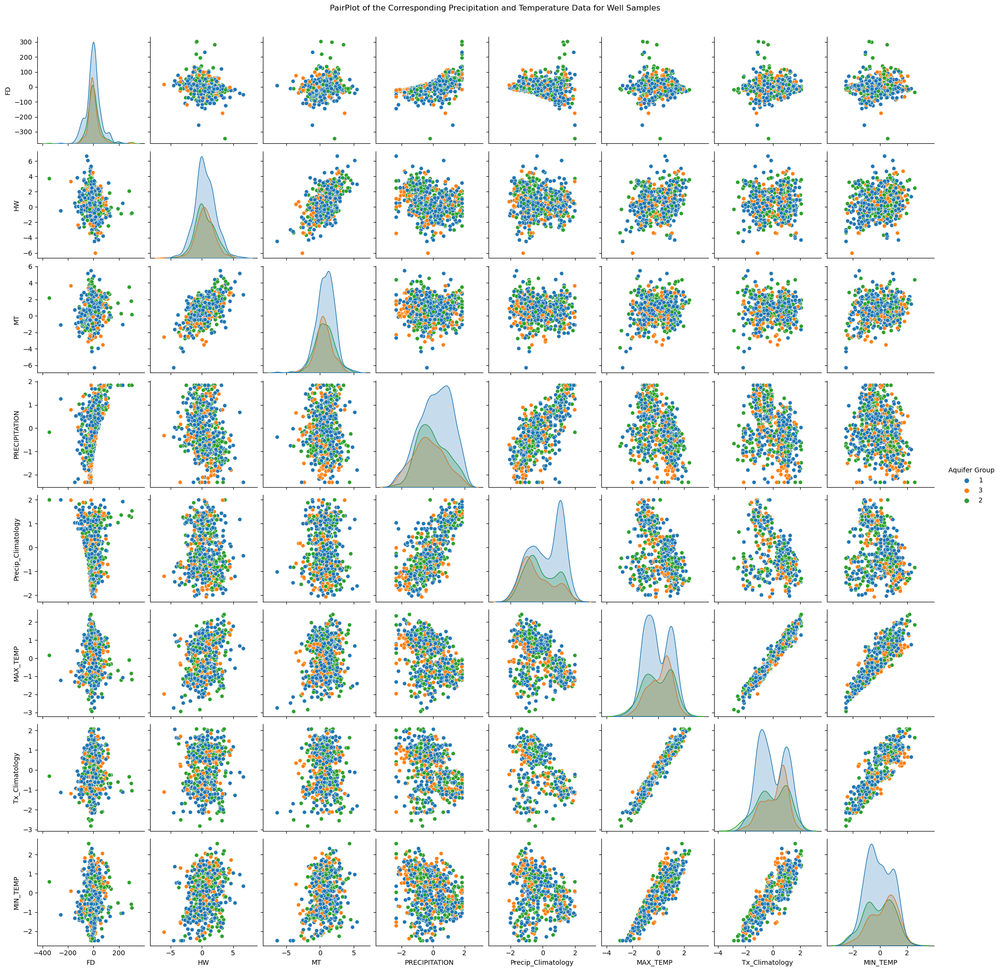

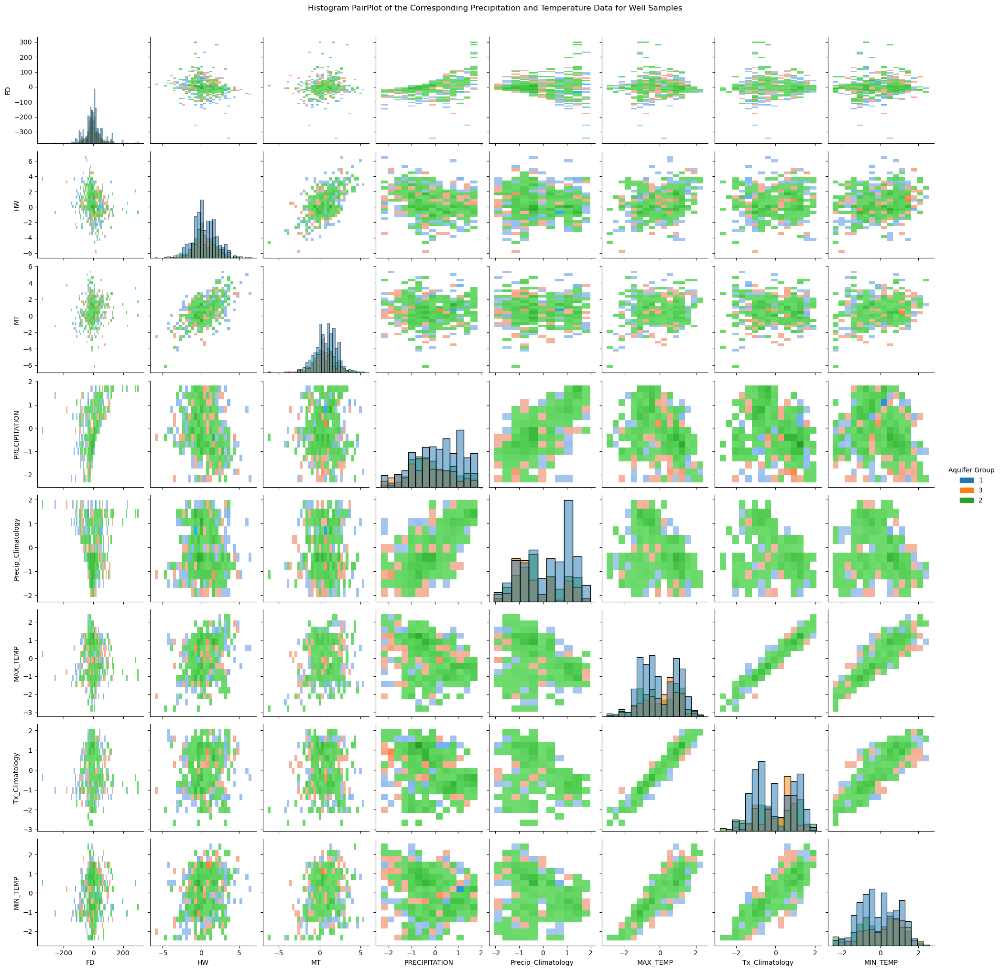

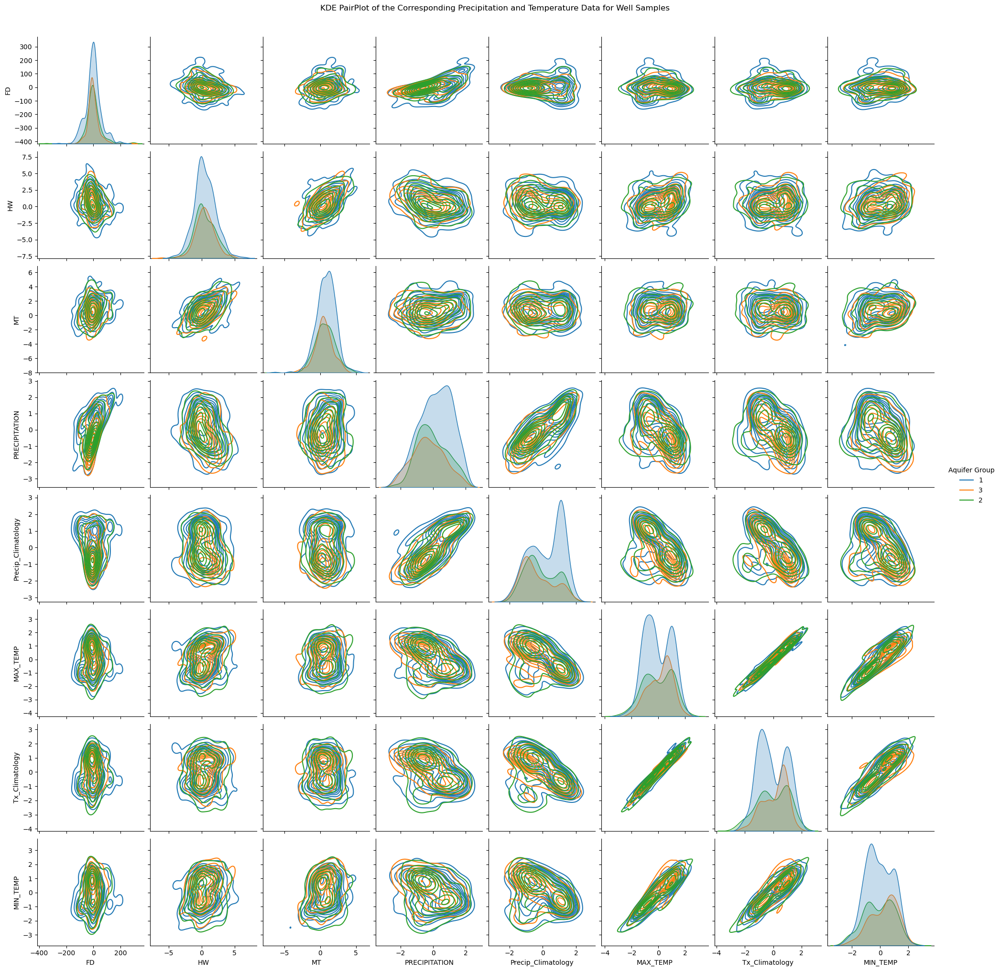

In [45]:
Preceptg= sns.pairplot(Precept, hue="Aquifer Group")
Preceptg.fig.suptitle("PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples", y=1.02)
plt.savefig('Figures/pairplotPrecept.png') # Save the first figure

Precepth = sns.pairplot(Precept, hue="Aquifer Group", kind="hist")
Precepth.fig.suptitle("Histogram PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples", y=1.02)
plt.savefig('Figures/histplotPrecept.png') 

Preceptf = sns.pairplot(Precept, hue="Aquifer Group", kind="kde")
Preceptf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data for Well Samples", y=1.02)
plt.savefig('Figures/KDEplotPrecept.png') 

In [46]:
OthersD = Datat[['Alkalinity Total 4.5', 'Ca-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
        'Aquifer Group']]
OthersD.shape

(985, 14)

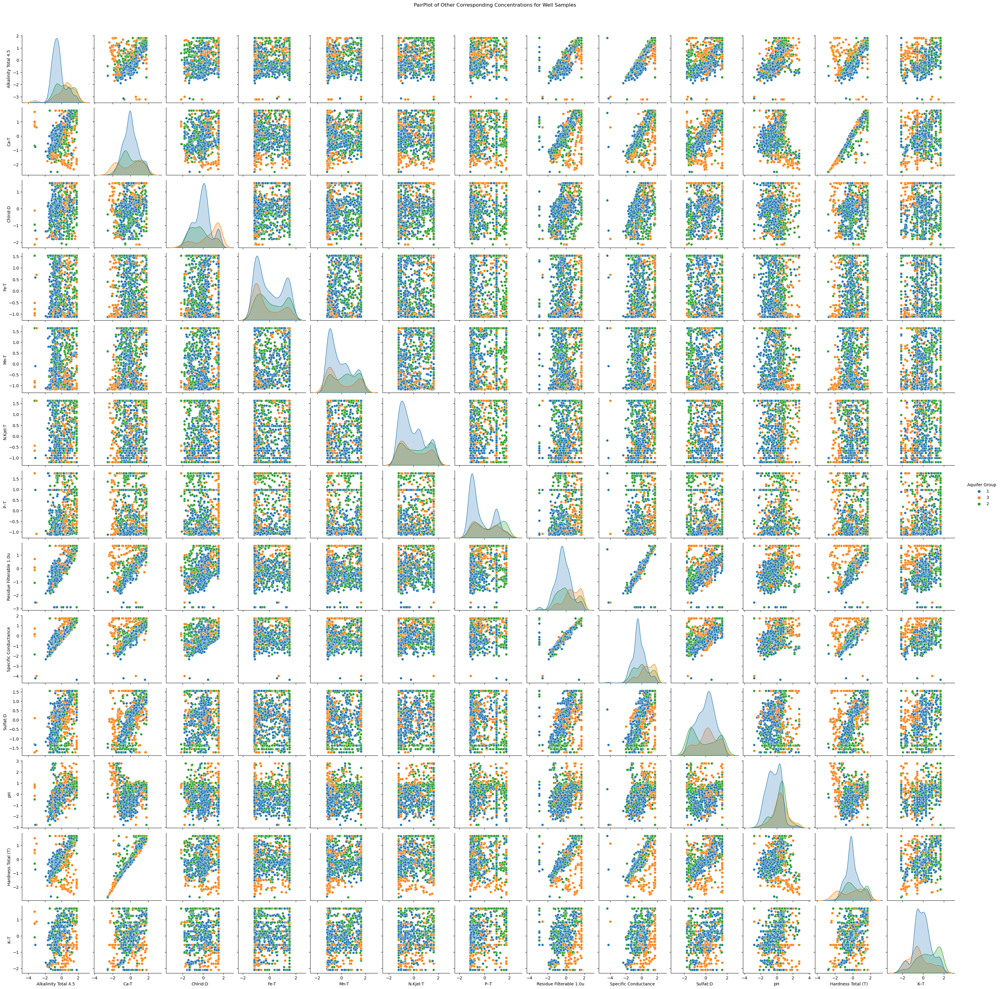

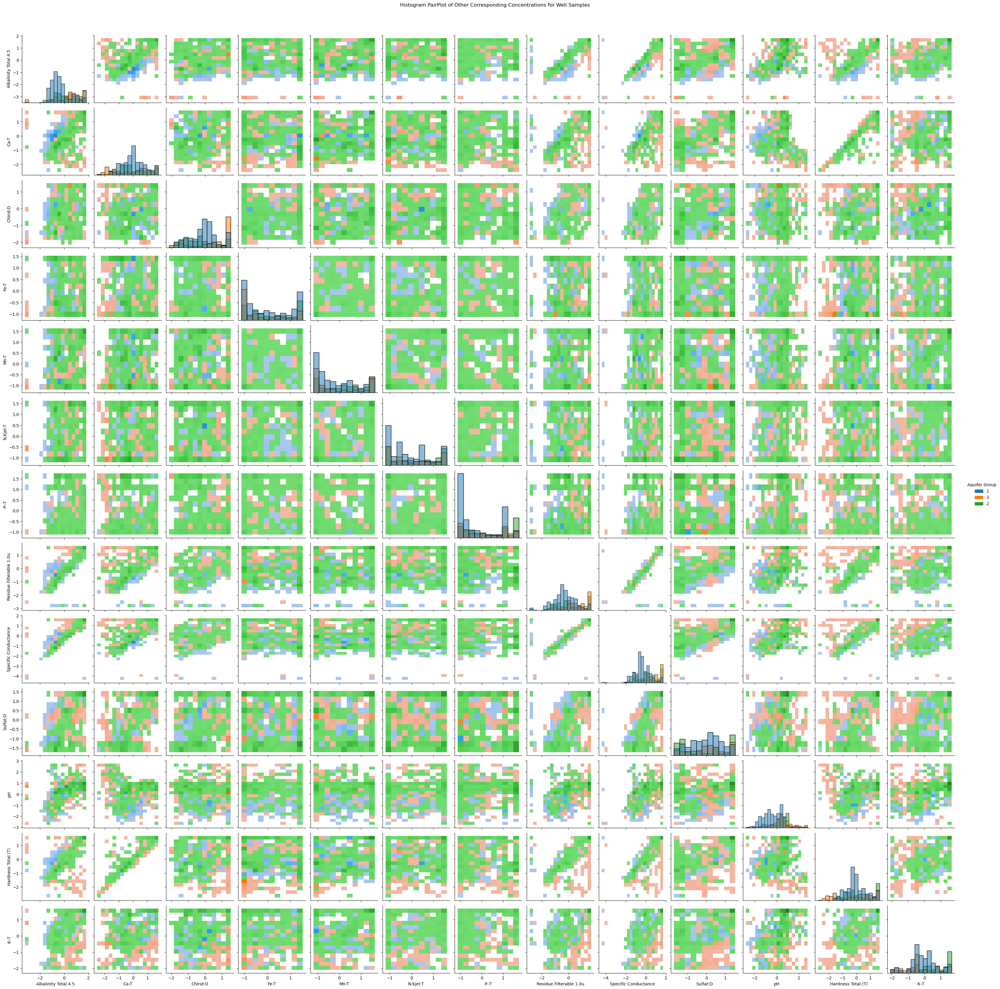

In [47]:
OthersDg= sns.pairplot(OthersD, hue="Aquifer Group")
OthersDg.fig.suptitle("PairPlot of Other Corresponding Concentrations for Well Samples", y=1.02)
plt.savefig('Figures/pairplotOthersD.png') # Save the first figure

OthersDh = sns.pairplot(OthersD, hue="Aquifer Group", kind="hist")
OthersDh.fig.suptitle("Histogram PairPlot of Other Corresponding Concentrations for Well Samples", y=1.02)
plt.savefig('Figures/histplotOthersD.png') 

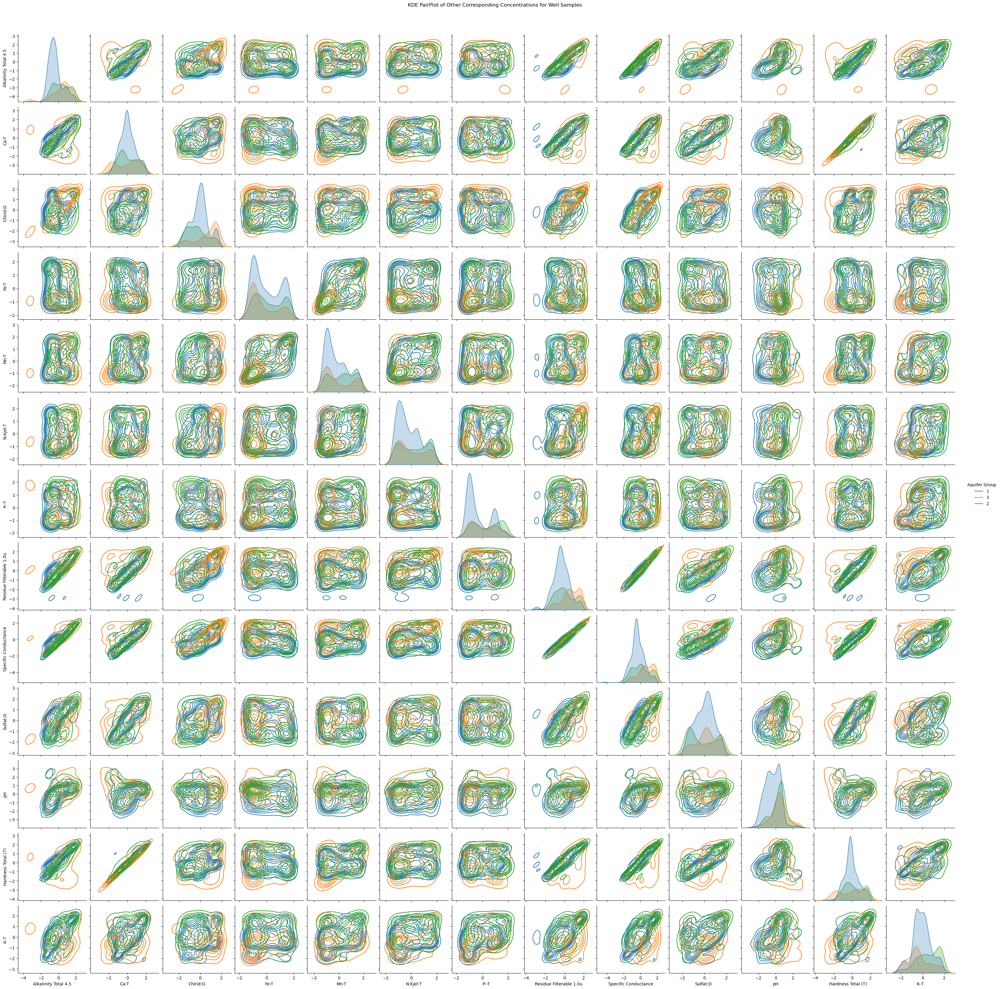

In [48]:
OthersDf = sns.pairplot(OthersD, hue="Aquifer Group", kind="kde")
OthersDf.fig.suptitle("KDE PairPlot of Other Corresponding Concentrations for Well Samples", y=1.02)
plt.savefig('Figures/KDEplotOthersD.png') 

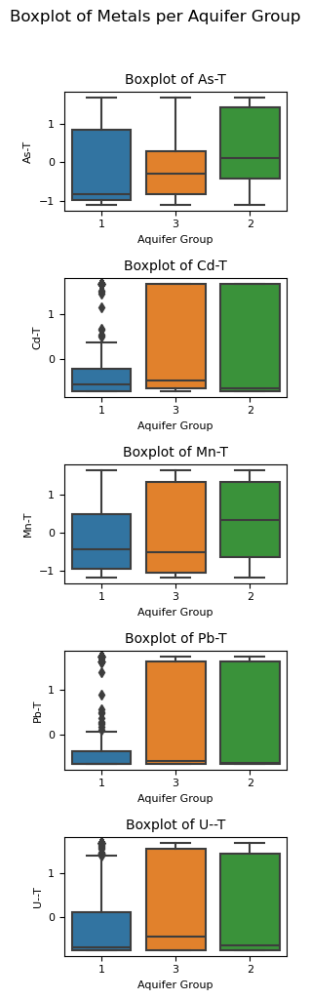

<Figure size 1000x800 with 0 Axes>

In [49]:
'''
Boxplots 

Source:
https://seaborn.pydata.org/generated/seaborn.boxplot.html
'''

import matplotlib.pyplot as plt

# Create a 5x1 grid of subplots
fig, axs = plt.subplots(5, 1, figsize=(3, 10))

# Create the boxplots
metals = ['As-T', 'Cd-T', 'Mn-T', 'Pb-T', 'U--T']
for i, metal in enumerate(metals):
    sns.boxplot(data=Metals_Total, x='Aquifer Group', y=metal, ax=axs[i])
    axs[i].set_title('Boxplot of ' + metal, fontsize=10)
    axs[i].tick_params(axis='x', labelsize=8) # set x-axis label size
    axs[i].tick_params(axis='y', labelsize=8)
    axs[i].set_ylabel(metal, fontsize=8) # set y-axis label and its size
    axs[i].set_ylabel(metal, fontsize=8) # set y-axis label and its size
    axs[i].set_xlabel('Aquifer Group', fontsize=8)
fig.suptitle("Boxplot of Metals per Aquifer Group", fontsize=12, y=1.02)
# Improve the layout
plt.tight_layout()
plt.show()
plt.savefig('Figures/boxplotmetals.png') 

# NEED HELP HERE 

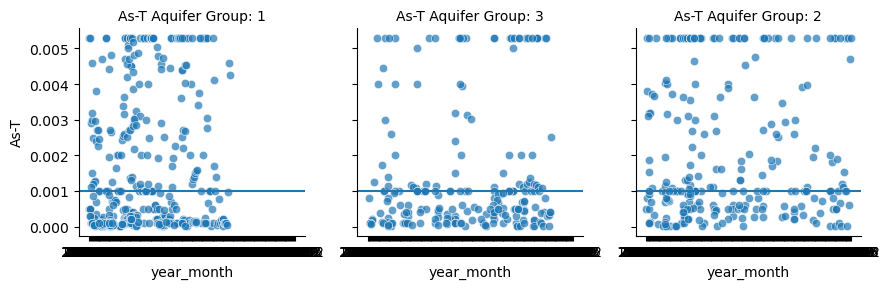

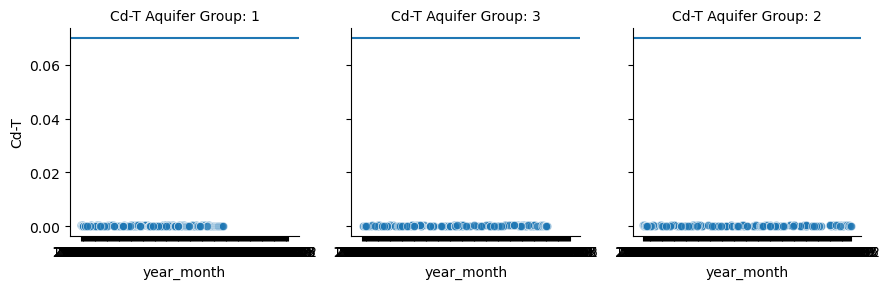

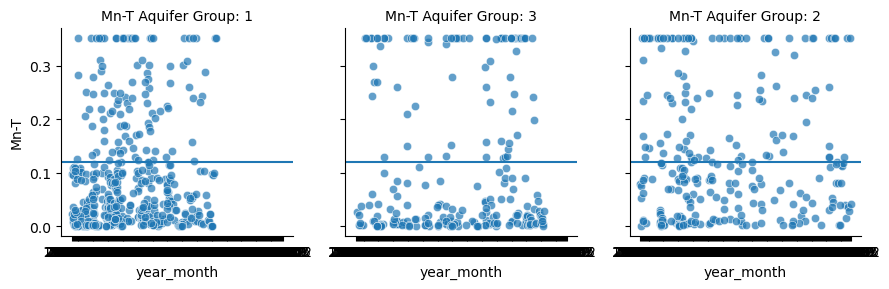

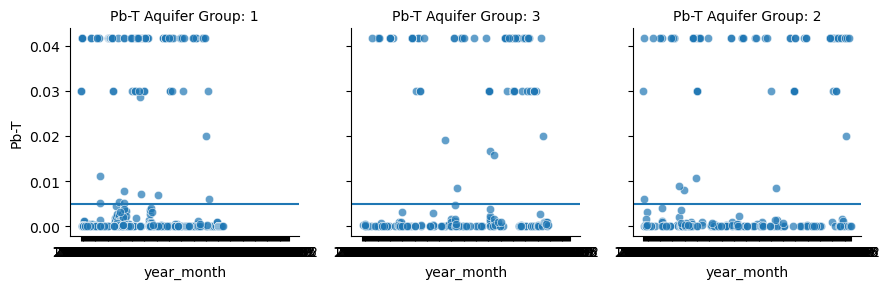

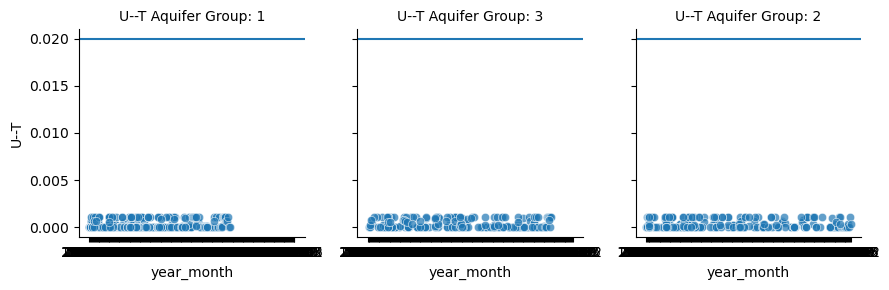

<Figure size 1000x800 with 0 Axes>

In [50]:
'''
Over Drinking water standards

**** Done on Power BI

Source:
https://seaborn.pydata.org/tutorial/axis_grids.html
https://www.statology.org/seaborn-add-line-to-scatterplot/
https://stackoverflow.com/questions/23833763/count-number-of-elements-in-each-column-less-than-x
'''
import matplotlib.pyplot as plt
import seaborn as sns

Total_Metals = Datawithtime_copy[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group', 'year_month']]

# Assuming Total_Metals DataFrame already exists
As = sns.FacetGrid(Total_Metals, col="Aquifer Group")
As.map(sns.scatterplot, "year_month", 'As-T', alpha=.7)
As.map(lambda x, **kwargs: plt.axhline(y=0.001, **kwargs), "year_month")
As.set_titles("As-T Aquifer Group: {col_name}")  # Setting title for each subplot

Cd = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Cd.map(sns.scatterplot, "year_month", 'Cd-T', alpha=.7)
Cd.map(lambda x, **kwargs: plt.axhline(y=0.07, **kwargs), "year_month")
Cd.set_titles("Cd-T Aquifer Group: {col_name}")  # Setting title for each subplot

Mn = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Mn.map(sns.scatterplot, "year_month", 'Mn-T', alpha=.7)
Mn.map(lambda x, **kwargs: plt.axhline(y=0.12, **kwargs), "year_month")
Mn.set_titles("Mn-T Aquifer Group: {col_name}")  # Setting title for each subplot

Pb = sns.FacetGrid(Total_Metals, col="Aquifer Group")
Pb.map(sns.scatterplot, "year_month", 'Pb-T', alpha=.7)
Pb.map(lambda x, **kwargs: plt.axhline(y=0.005, **kwargs), "year_month")
Pb.set_titles("Pb-T Aquifer Group: {col_name}")  # Setting title for each subplot

UT = sns.FacetGrid(Total_Metals, col="Aquifer Group")
UT.map(sns.scatterplot, "year_month", 'U--T', alpha=.7)
UT.map(lambda x, **kwargs: plt.axhline(y=0.02, **kwargs), "year_month")
UT.set_titles("U--T Aquifer Group: {col_name}")  # Setting title for each subplot

#plt.suptitle("Well Water Samples with As, Mn, Pb and U Concentrations over Canadian Drinking Water Standards", fontsize=12, y=1.02)
plt.tight_layout()  # This line is to prevent overlapping of the title and the top plot
plt.show()
plt.savefig('Figures/metalsoverCADdrinkingwater.png') 


In [51]:
Datawithtime.columns

Index(['OBSWELL', 'DATE', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T',
       'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T',
       'Residue Filterable 1.0u', 'Specific Conductance', 'Sulfat:D', 'pH',
       'Hardness Total (T)', 'K--T', 'U--T', 'year_month', 'PRECIPITATION',
       'MIN_TEMP', 'MAX_TEMP', 'Precip_Climatology', 'Tn_Climatology',
       'Tx_Climatology', 'FD', 'HW', 'MT', 'Aquifer Group'],
      dtype='object')

In [70]:
CANDMetalspre = Datawithtime_copy[['OBSWELL', 'As-T', 'Mn-T', 'Pb-T', 'U--T']]

filtered_dfAs = CANDMetalspre[(CANDMetalspre['As-T'] >= 0.001)]
obs_well_valuesAs = filtered_dfAs['OBSWELL']
obs_well_valuesAs.shape

(431,)

In [53]:
filtered_dfMn = CANDMetalspre[(CANDMetalspre['Mn-T'] >= 0.12)]
obs_well_valuesMn = filtered_dfMn['OBSWELL']
obs_well_valuesMn.shape

(297,)

In [54]:
filtered_dfPb = CANDMetalspre[(CANDMetalspre['Pb-T'] >= 0.005)]
obs_well_valuesPb = filtered_dfPb['OBSWELL']
obs_well_valuesPb.shape

(262,)

In [55]:
filtered_dfU = CANDMetalspre[(CANDMetalspre['U--T'] >= 0.02)]
obs_well_valuesU = filtered_dfU['OBSWELL']
obs_well_valuesU.shape


(0,)

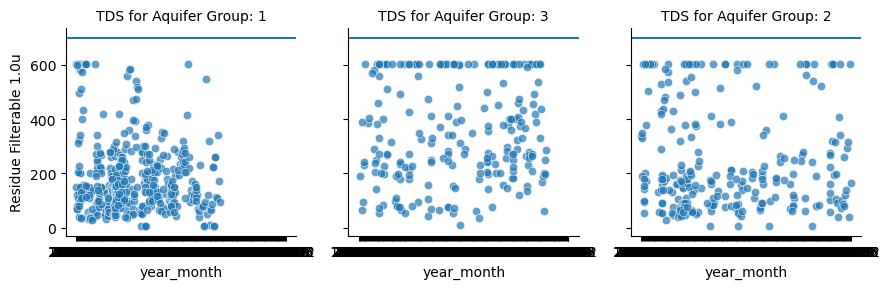

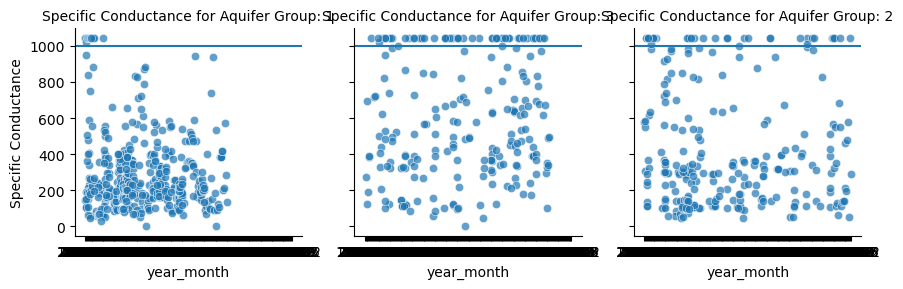

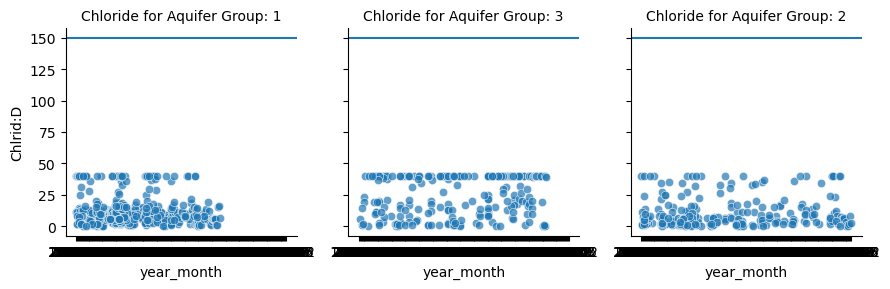

In [56]:
'''
Graphs of Saltwater intrusion
'''
SI_values = Datawithtime_copy[['year_month', 'Residue Filterable 1.0u','Specific Conductance', 'Chlrid:D', 'Aquifer Group']]


TDS = sns.FacetGrid(SI_values, col="Aquifer Group")
TDS.map(sns.scatterplot, "year_month", "Residue Filterable 1.0u", alpha=.7)
TDS.map(lambda x, **kwargs: plt.axhline(y=700, **kwargs), "year_month")
TDS.set_titles("TDS for Aquifer Group: {col_name}")  # Setting title for each subplot

SC = sns.FacetGrid(SI_values, col="Aquifer Group")
SC.map(sns.scatterplot, "year_month", 'Specific Conductance', alpha=.7)
SC.map(lambda x, **kwargs: plt.axhline(y=1000, **kwargs), "year_month")
SC.set_titles("Specific Conductance for Aquifer Group: {col_name}")  # Setting title for each subplot

Cld = sns.FacetGrid(SI_values, col="Aquifer Group")
Cld.map(sns.scatterplot, 'year_month', 'Chlrid:D', alpha=.7)
Cld.map(lambda x, **kwargs: plt.axhline(y=150, **kwargs), "year_month")
Cld.set_titles("Chloride for Aquifer Group: {col_name}")  # Setting title for each subplot

plt.savefig('Figures/SIoverwellstime.png') 

In [57]:
SWInow = Datawithtime_copy[['OBSWELL', 'Residue Filterable 1.0u','Specific Conductance', 'Chlrid:D',]]

filtered_dTDS = SWInow[(SWInow['Residue Filterable 1.0u'] >= 750)]
obs_well_valuesTDS = filtered_dTDS['OBSWELL']
obs_well_valuesTDS.shape

(0,)

In [58]:
filtered_dSC = SWInow[(SWInow['Specific Conductance'] >= 1000)]
obs_well_valuesSC = filtered_dSC['OBSWELL']
obs_well_valuesSC.shape

(101,)

In [59]:
filtered_dC = SWInow[(SWInow['Chlrid:D'] >= 150)]
obs_well_valuesC = filtered_dC['OBSWELL']
obs_well_valuesC.shape

(0,)

In [60]:
Datawithtime.columns

Index(['OBSWELL', 'DATE', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T',
       'Chlrid:D', 'Fe-T', 'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T',
       'Residue Filterable 1.0u', 'Specific Conductance', 'Sulfat:D', 'pH',
       'Hardness Total (T)', 'K--T', 'U--T', 'year_month', 'PRECIPITATION',
       'MIN_TEMP', 'MAX_TEMP', 'Precip_Climatology', 'Tn_Climatology',
       'Tx_Climatology', 'FD', 'HW', 'MT', 'Aquifer Group'],
      dtype='object')

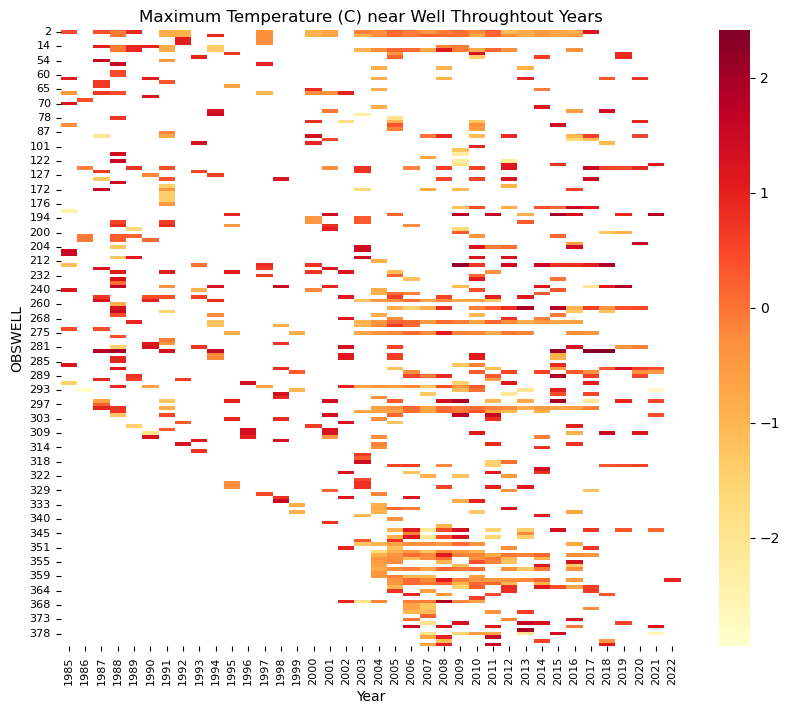

<Figure size 1000x800 with 0 Axes>

In [72]:
'''
Date Time Visualization

Note:  Could do a median polish but that's too compentionally difficult and my times series is not consistent
Source: 
https://towardsdatascience.com/8-visualizations-with-python-to-handle-multiple-time-series-data-19b5b2e66dd0

'''

Datawithtime['DATE'] = pd.to_datetime(Datawithtime['DATE'])
Datawithtime['Year'] = Datawithtime['DATE'].dt.year

# Pivot the DataFrame
TempH = Datawithtime.pivot_table(index="OBSWELL", columns="Year", values="MAX_TEMP")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(TempH, annot=False, cmap='YlOrRd')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Maximum Temperature (C) near Well Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/maxtemp.png') 



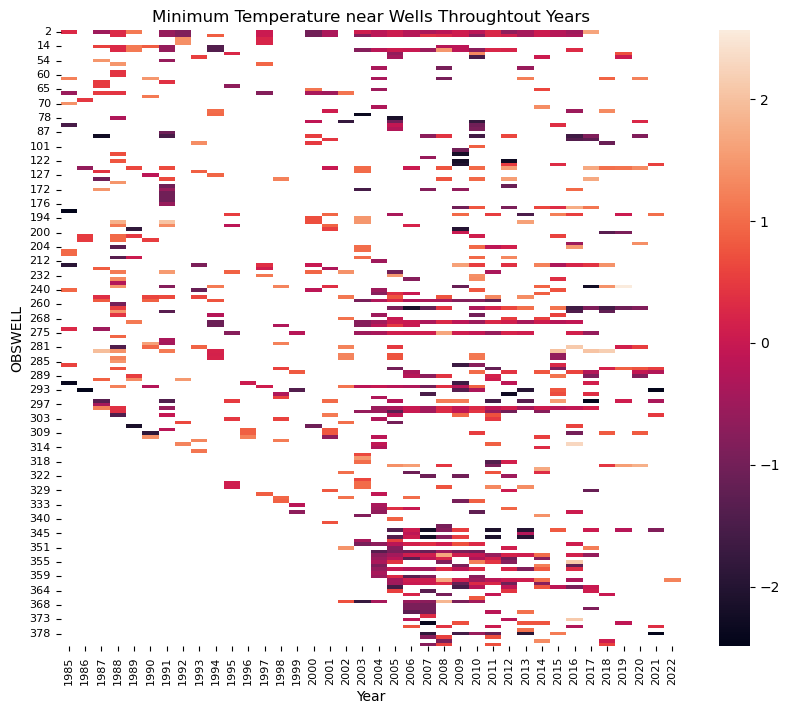

<Figure size 1000x800 with 0 Axes>

In [62]:
# Pivot the DataFrame
TempMin = Datawithtime.pivot_table(index="OBSWELL", columns="Year", values="MIN_TEMP")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(TempMin, annot=False, cmap='YlOrRd')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Minimum Temperature near Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/MinTempHeatmap.png') 


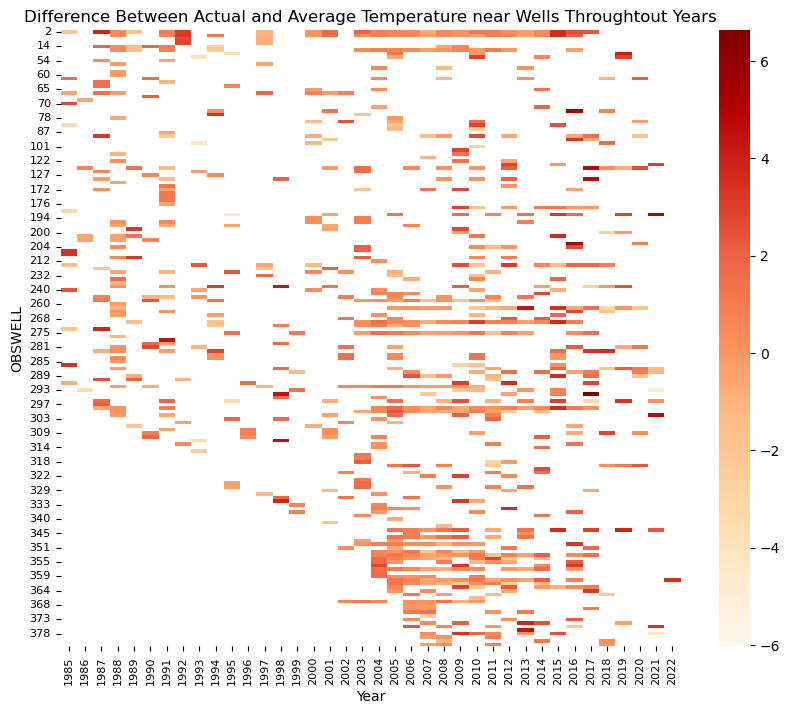

<Figure size 1000x800 with 0 Axes>

In [71]:
# Pivot the DataFrame
HWa = Datawithtime.pivot_table(index="OBSWELL", columns="Year", values="HW")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(HWa, annot=False, cmap='YlOrRd')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Difference Between Actual and Average Temperature near Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/HeatMapHeatWave.png') 




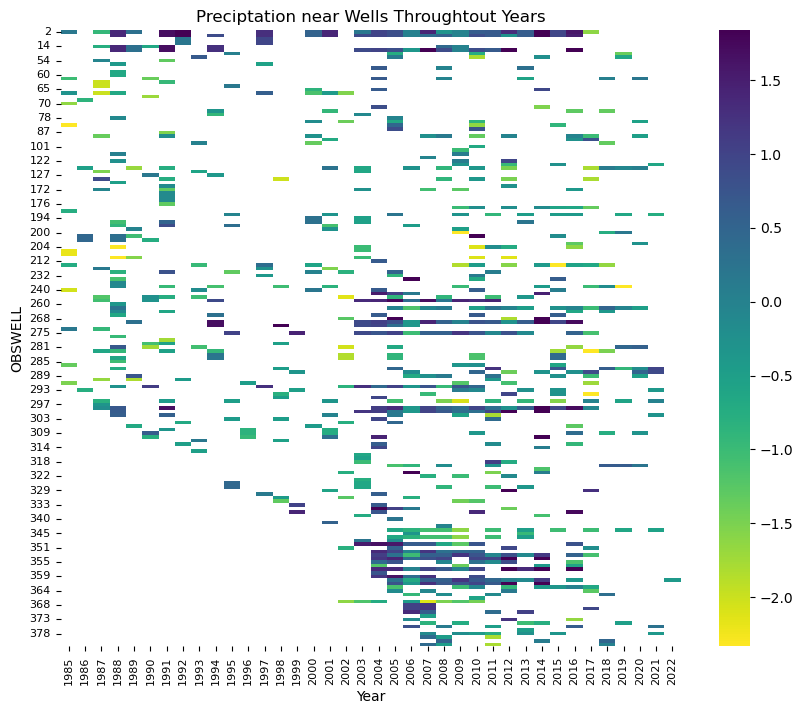

<Figure size 1000x800 with 0 Axes>

In [64]:
# Pivot the DataFrame
Percp = Datawithtime.pivot_table(index="OBSWELL", columns="Year", values="PRECIPITATION")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(Percp, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Precipitation  near Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/HeatMapPRECIPITATION.png') 


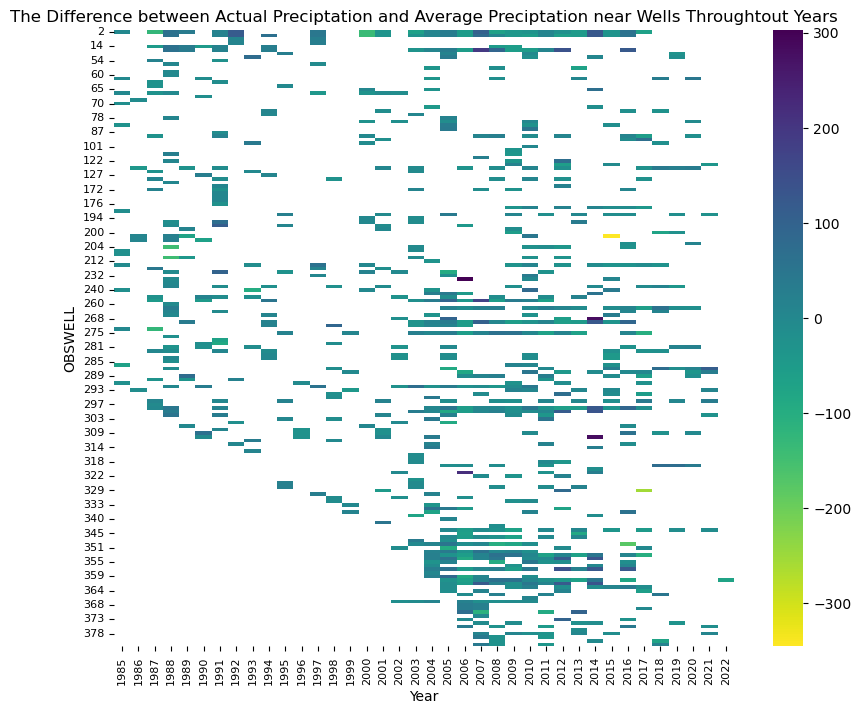

<Figure size 1000x800 with 0 Axes>

In [65]:
# Pivot the DataFrame
PercpHD = Datawithtime.pivot_table(index="OBSWELL", columns="Year", values="FD")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(PercpHD, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('The Difference between Actual Precipitation and Stimulated Precipitation  near Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/HeatMapFlooddrought.png') 

In [7]:
SWISC = Datawithtime.pivot_table(index="OBSWELL", columns="Year", values="Specific Conductance")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWISC, annot=False, cmap='viridis_r')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Specific Conductance Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapSC.png') 

KeyError: 'Year'

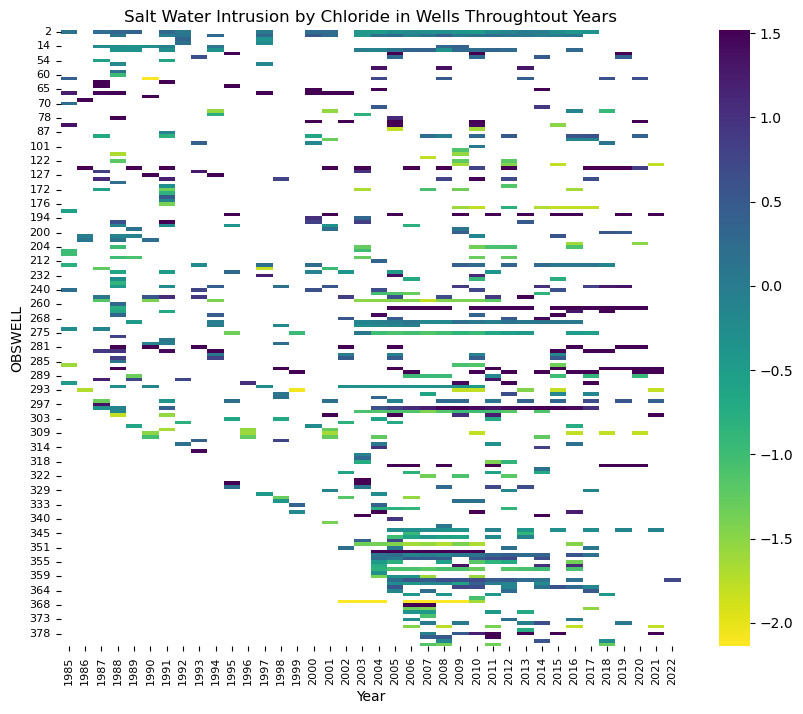

<Figure size 1000x800 with 0 Axes>

In [67]:
SWICDL = Datawithtime.pivot_table(index="OBSWELL", columns="Year", values="Chlrid:D")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWICDL, annot=False, cmap='viridis')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by Chloride in Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapClScaled.png') 

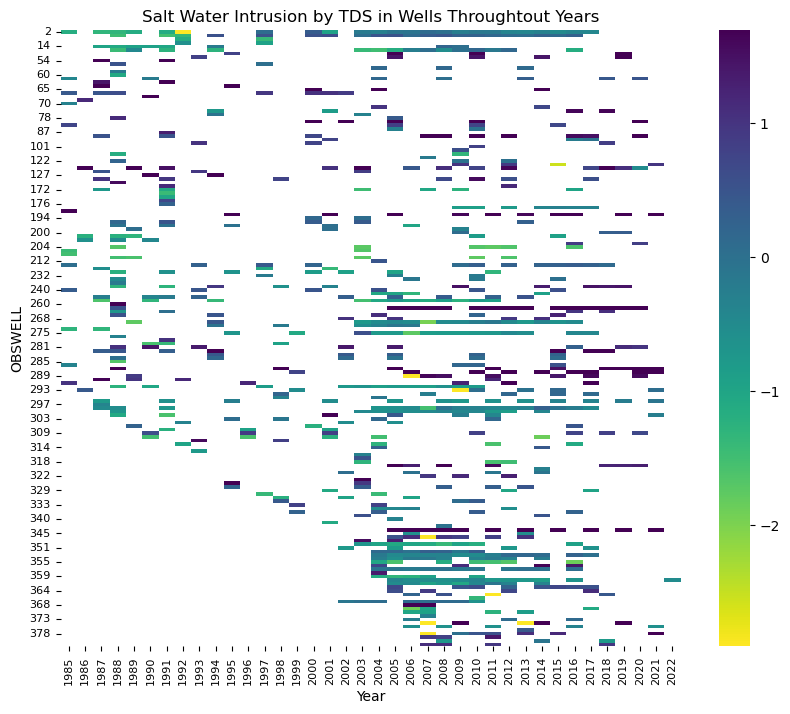

<Figure size 1000x800 with 0 Axes>

In [68]:
SWItds = Datawithtime.pivot_table(index="OBSWELL", columns="Year", values="Residue Filterable 1.0u")

# Create the heatmap
plt.figure(figsize=(10,8))  # optionally set the figure size
ax = sns.heatmap(SWItds, annot=False, cmap='viridis')
# Set the size of the x and y tick labels
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
plt.title('Salt Water Intrusion by TDS in Wells Throughtout Years')  # add a title
plt.show()
plt.savefig('Figures/SWIheatmapTDSScaled.png') 